## Import packages ###

In [1]:
import os

##### Data Management
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
from scipy.special import erf
from lmfit import Model

## Import own functions ###

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.fitting.analysis import Diffusion_Erf_Model
from scientific_utils.fitting.analysis import Objective_Diffusion_Fit
from scientific_utils.fitting.analysis import Solve_Diffusion
from scientific_utils.fitting.analysis import Step_Function_Initial_Condition
from scientific_utils.general.analysis import Normalize_Column_To_Reference_Column
from scientific_utils.impedance.analysis import Calculate_Impedance_RC_Model
from scientific_utils.impedance.analysis import Fit_Z_Real_Imag_RCRCRCCPE
from scientific_utils.impedance.plotting import Matplotlib_Nyquist_Plot
from scientific_utils.tof_sims.io import Read_SurfaceLab_DepthProfil_Combined_Header
from scientific_utils.tof_sims.plotting import Plotly_DepthProfil
from scientific_utils.tof_sims.plotting import Plotly_DepthProfil_Multiple_YAxis
from scientific_utils.publication_plotly import my_color_scale # colours of the publication style

## Create output folder

In [3]:
# create the output folder of it not yet exists
data_outdir = './saved_data/'
if not os.path.exists(data_outdir):
    os.mkdir(data_outdir)

In [4]:
# create the output folder of it not yet exists
images_outdir = './images/'
if not os.path.exists(images_outdir):
    os.mkdir(images_outdir)

# ===============
# Plotting Raw Data

## Read data

In [5]:
a = path = './data/raw'
b = FilterByNameList = ['20240613']
c = FileFormat = '.txt'
d = seperation_of_the_values = '\t'

depth_profils, file_names = Read_SurfaceLab_DepthProfil_Combined_Header(a, b, c , d)

-------------------
Following Files found in the chosen directory: %s ['20240523_scNCM_30MinWashed_-70Cryo_Spot01intdepht.txt', '20240524_scNCM_overnightWashed_-70Cryo_Spot01intdepth.txt', '20240613_scNCM_OneWeekWashed_Cryo-70_Spot1intdepth.txt']
-------------------
[]
Files found: ['20240613_scNCM_OneWeekWashed_Cryo-70_Spot1intdepth.txt']
-------------------
In total 1 files are selected. 
The name of the files are: 
['20240613_scNCM_OneWeekWashed_Cryo-70_Spot1intdepth.txt']
-------------------
['#', 'NiO_2-', 'CoO_2-', 'MnO_3-', 'NiO_2^2H-', '^2HLiNi_2O_4-']
['#Depth (nm)', 'Intensity(Raw, Background Corrected)', 'Intensity(Raw, Background Corrected)', 'Intensity(Raw, Background Corrected)', 'Intensity(Raw, Background Corrected)', 'Intensity(Raw, Background Corrected)']
['148,759', '1,82115e+06', '507143', '344267', '38573', '11329,9']
6
6


In [6]:
depth_profils[0]

,##Depth (nm),"NiO_2-Intensity(Raw, Background Corrected)","CoO_2-Intensity(Raw, Background Corrected)","MnO_3-Intensity(Raw, Background Corrected)","NiO_2^2H-Intensity(Raw, Background Corrected)","^2HLiNi_2O_4-Intensity(Raw, Background Corrected)"
0,6.467800,207030.0,63835.8,48271.7,12875.3,115.761
1,19.403400,583884.0,167869.0,112716.0,24707.0,1468.160
2,32.339001,877453.0,249316.0,168986.0,32768.5,3697.250
3,45.274601,1066940.0,297091.0,201503.0,36063.9,4715.350
4,58.210201,1210460.0,339193.0,229612.0,38264.6,6359.120
...,...,...,...,...,...,...
145,1882.130005,3761800.0,1067450.0,518730.0,24652.8,43112.700
146,1895.069946,3788980.0,1071850.0,524831.0,24568.0,44054.300
147,1908.000000,3802280.0,1074510.0,528166.0,24053.8,44860.600
148,1920.939941,3842200.0,1087160.0,529439.0,25092.1,45503.300


## Plotting Raw Data

In [7]:
a = Dataframe = depth_profils[0]
b = x_column_name = '##Depth (nm)'
c = list_of_y_column_names = ['NiO_2-Intensity(Raw, Background Corrected)', '^2HLiNi_2O_4-Intensity(Raw, Background Corrected)', 'NiO_2^2H-Intensity(Raw, Background Corrected)']
d = list_of_curve_label = ['NiO_2', '^2HLiNi_2O_4', 'NiO_2^2H']
e = list_of_colors = ['royalblue', 'red', 'green']
f = XAxis_Label = '<i> Depth </i> / nm'
g = YAxis_Label = '<i> Counts </i>'
h = Filepath_for_saving = images_outdir + 'OneWeekWashed' + '.html'

Plotly_DepthProfil(a, b, c , d, e, f, g, h)

In [8]:
a = Dataframe = depth_profils[0]
b = x_column_name = '##Depth (nm)'
c = list_of_y_column_names = ['NiO_2-Intensity(Raw, Background Corrected)', '^2HLiNi_2O_4-Intensity(Raw, Background Corrected)', 'NiO_2^2H-Intensity(Raw, Background Corrected)']
d = list_of_curve_label = ['NiO_2', '^2HLiNi_2O_4', 'NiO_2^2H']
e = list_of_colors = ['royalblue', 'red', 'green']
f = XAxis_Label = '<i> Depth </i> / nm'
g = YAxis_Label = '<i> Counts </i>'
h = Filepath_for_saving = images_outdir + 'OneWeekWashed_MultipleYAxis' + '.html'

Plotly_DepthProfil_Multiple_YAxis(a, b, c , d, e, f, g, h)

# ===============
# Fitting Diff Profil via 2. Ficksche Gesetz where D is independent of C
### Fitting Concentration independet Diffusion via Analytical Solution

## Calculation

In [9]:
## Normalzie to NiO2 Signal Intensity
#Dataframe Kopieren
depth_profils_normalized = depth_profils[0].copy()

#Normalise the dataframe to NiO2
a = dataframe = depth_profils_normalized
for i in dataframe.columns.tolist():
    b = column_name1 = i
    c = column_name2 = 'NiO_2-Intensity(Raw, Background Corrected)'

    Normalize_Column_To_Reference_Column(a, b, c)

In [10]:
depth_profils_normalized

,##Depth (nm),"NiO_2-Intensity(Raw, Background Corrected)","CoO_2-Intensity(Raw, Background Corrected)","MnO_3-Intensity(Raw, Background Corrected)","NiO_2^2H-Intensity(Raw, Background Corrected)","^2HLiNi_2O_4-Intensity(Raw, Background Corrected)","##Depth (nm)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)","NiO_2-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)","CoO_2-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)","MnO_3-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)","NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)","^2HLiNi_2O_4-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)"
0,6.467800,207030.0,63835.8,48271.7,12875.3,115.761,0.000031,1.0,0.308341,0.233163,0.062191,0.000559
1,19.403400,583884.0,167869.0,112716.0,24707.0,1468.160,0.000033,1.0,0.287504,0.193045,0.042315,0.002514
2,32.339001,877453.0,249316.0,168986.0,32768.5,3697.250,0.000037,1.0,0.284136,0.192587,0.037345,0.004214
3,45.274601,1066940.0,297091.0,201503.0,36063.9,4715.350,0.000042,1.0,0.278451,0.188861,0.033801,0.004420
4,58.210201,1210460.0,339193.0,229612.0,38264.6,6359.120,0.000048,1.0,0.280218,0.189690,0.031612,0.005253
...,...,...,...,...,...,...,...,...,...,...,...,...
145,1882.130005,3761800.0,1067450.0,518730.0,24652.8,43112.700,0.000500,1.0,0.283760,0.137894,0.006553,0.011461
146,1895.069946,3788980.0,1071850.0,524831.0,24568.0,44054.300,0.000500,1.0,0.282886,0.138515,0.006484,0.011627
147,1908.000000,3802280.0,1074510.0,528166.0,24053.8,44860.600,0.000502,1.0,0.282596,0.138908,0.006326,0.011798
148,1920.939941,3842200.0,1087160.0,529439.0,25092.1,45503.300,0.000500,1.0,0.282952,0.137796,0.006531,0.011843


In [11]:
a = Dataframe = depth_profils_normalized
b = x_column_name = '##Depth (nm)'
c = list_of_y_column_names = ['NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)', '^2HLiNi_2O_4-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)']
d = list_of_curve_label = ['^2HLiNi_2O_4', 'NiO_2^2H']
e = list_of_colors = ['red', 'green']
f = XAxis_Label = '<i> Depth </i> / nm'
g = YAxis_Label = '<i> Counts </i>'
h = Filepath_for_saving = images_outdir + 'OneWeekWashed_MultipleYAxis_Normalized' + '.html'

Plotly_DepthProfil_Multiple_YAxis(a, b, c , d, e, f, g, h)

In [12]:
y_data_eval2 = depth_profils_normalized['NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)']
x_data_eval2 = depth_profils_normalized['##Depth (nm)']

## Errorfunction for Fitting

In [13]:
from lmfit import Parameters, minimize
from lmfit.printfuncs import report_fit

x_data = np.linspace(-100, 100000, 1000) # depth in nm

### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('D', value=2.8e-12 * 1e14)
FitParameters.add('A', value=0.10, max=1.0, min=0.01)
FitParameters.add('t', value=43200, max=53200, min=33200)

y_data = Diffusion_Erf_Model(FitParameters, x_data, None, residual_func=False)

# Add some noise to the data
y_data_noisy = y_data + 0.0001 * np.random.normal(size=x_data.size)

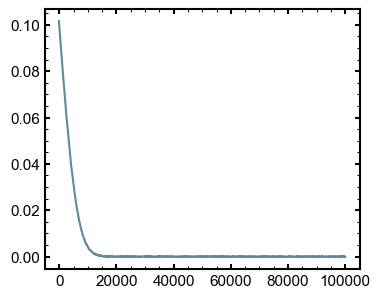

In [14]:
plt.plot(x_data, y_data_noisy)

## Fitting 

In [15]:
depth_profils_normalized['NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)'].iloc[-1]

np.float64(0.006610463758337009)

In [16]:
y_data = depth_profils_normalized['NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)'].iloc[::] - depth_profils_normalized['NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)'].iloc[-1]
x_data = depth_profils_normalized['##Depth (nm)'].iloc[::]

In [17]:
y_data

0      0.055580
1      0.035704
2      0.030735
3      0.027191
4      0.025001
         ...   
145   -0.000057
146   -0.000126
147   -0.000284
148   -0.000080
149    0.000000
Name: NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected), Length: 150, dtype: float64

In [18]:
x_data

0         6.467800
1        19.403400
2        32.339001
3        45.274601
4        58.210201
          ...     
145    1882.130005
146    1895.069946
147    1908.000000
148    1920.939941
149    1933.869995
Name: ##Depth (nm), Length: 150, dtype: float32

In [19]:
# Check if there are NaN values
has_nan = x_data.isna().any()
print(f"Series contains NaN values: {has_nan}")

# Check if there are NaN values
has_nan = y_data.isna().any()
print(f"Series contains NaN values: {has_nan}")

Series contains NaN values: False
Series contains NaN values: False


In [20]:
from lmfit import Parameters, minimize
from lmfit.printfuncs import report_fit

# # real data
# y_data = depth_profils_normalized['NiO_2^2H-Intensity(Raw, Background Corrected)_normalized_to_NiO_2-Intensity(Raw, Background Corrected)']
# x_data = depth_profils_normalized['##Depth (nm)']

# modeled data
# x_data = x_data 
# y_data = y_data_noisy

### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('D', value=2.5e-15 * 1e14, min=1.0e-15 * 1e2, max=1.0e-15 * 1e19)
#FitParameters.add('A', value=0.05, min=0.001, max=1.0)
#FitParameters.add('A', value=y_data[0], vary=False)
FitParameters.add('A', value=0.0135, vary=False)
FitParameters.add('t', value=604800, vary=False)

# Searches the minimum of the residual function
residual_func = True
result = minimize(fcn=Diffusion_Erf_Model, params=FitParameters,  args=(x_data, y_data, residual_func), method='basinhopping', max_nfev=100000, nan_policy='raise')#, xtol=1e-10, ftol=1e-10)

In [21]:
report_fit(result, show_correl=False, modelpars=FitParameters)

[[Fit Statistics]]
    # fitting method   = basinhopping
    # function evals   = 422
    # data points      = 150
    # variables        = 1
    chi-square         = 0.01907718
    reduced chi-square = 1.2803e-04
    Akaike info crit   = -1343.48463
    Bayesian info crit = -1340.47400
##  Warning: uncertainties could not be estimated:
[[Variables]]
    D:  186.223834 (init = 0.25), model_value = 0.25
    A:  0.0135 (fixed)
    t:  604800 (fixed)


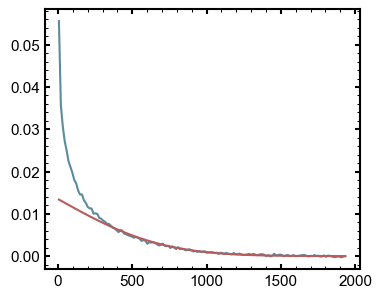

In [22]:
### Optimierte Parameter
Parameters = result.params

### Calculate the y data
y_data_fitted = Diffusion_Erf_Model(FitParameters, x_data, None, residual_func=False)

# Plot
plt.plot(x_data, y_data, c=my_color_scale[4])
plt.plot(x_data, y_data_fitted, c=my_color_scale[0])

In [23]:
import plotly.graph_objects as go
from scientific_utils.publication_plotly import apply_style, OVERVIEW_W_CM, OVERVIEW_H_CM, SHOW_LEGEND

##### Define Figure
# 1. Wrap the Plotly-Figure with the FigureResampler
fig = go.Figure()
            
##### Add Scatter plots and change style
fig.add_scatter(
    x=x_data, 
    y=y_data, 
    name='data', 
    mode='lines',  # set the mode to 'markers+lines'
    line=dict(
        color=my_color_scale[4],  # set the line colour to red
        width=2,  # set the line width to 2
        dash='solid'  
    )
    )

fig.add_scatter(
    x=x_data, 
    y=y_data_fitted, 
    name='fit', 
    mode='lines',  # set the mode to 'markers+lines'
    line=dict(
        color=my_color_scale[0],  # set the line colour to red
        width=2,  # set the line width to 2
        dash='solid'  
    )
    )
    
##### Change Visual Layout of the Plot: publication style, size and legend are set in publication_plotly.py
apply_style(fig, XAxis_Label, YAxis_Label, plot_w_cm=OVERVIEW_W_CM, plot_h_cm=OVERVIEW_H_CM,
            x_tickformat='uniform', y_tickformat='uniform', showlegend=SHOW_LEGEND)

# Save Plot as interactive html Plot
#fig.write_html(Filepath_for_saving) # images_outdir + "Comparing_specCapacites" + ".html"

fig.show()


In [24]:
import plotly.graph_objects as go
from scientific_utils.publication_plotly import apply_style, OVERVIEW_W_CM, OVERVIEW_H_CM, SHOW_LEGEND

##### Define Figure
# 1. Wrap the Plotly-Figure with the FigureResampler
fig = go.Figure()
            
##### Add Scatter plots and change style
fig.add_scatter(
    x=x_data, 
    y=y_data, 
    name='data', 
    mode='lines',  # set the mode to 'markers+lines'
    line=dict(
        color=my_color_scale[4],  # set the line colour to red
        width=2,  # set the line width to 2
        dash='solid'  
    )
    )

fig.add_scatter(
    x=x_data, 
    y=y_data_fitted, 
    name='fit', 
    mode='lines',  # set the mode to 'markers+lines'
    line=dict(
        color=my_color_scale[0],  # set the line colour to red
        width=2,  # set the line width to 2
        dash='solid'  
    )
    )
    
##### Change Visual Layout of the Plot: publication style, size and legend are set in publication_plotly.py
apply_style(fig, XAxis_Label, YAxis_Label, plot_w_cm=OVERVIEW_W_CM, plot_h_cm=OVERVIEW_H_CM,
            x_tickformat='uniform', y_tickformat='uniform', showlegend=SHOW_LEGEND)

# Save Plot as interactive html Plot
#fig.write_html(Filepath_for_saving) # images_outdir + "Comparing_specCapacites" + ".html"

fig.show()


# ===============
# Fitting Diff Profil via 2. Ficksche Gesetz where D is dependent of C
### Fitting Concentration dependet Diffusion via Numerical Simulation

In [25]:
from lmfit import Parameters, minimize
from lmfit.printfuncs import report_fit

x_data = np.linspace(0, 200, 200) # depth

### Start values for the optimisation and their limits
FitParameters = Parameters()
FitParameters.add('D', value=10)
FitParameters.add('A', value=1, min=0.01, max=1.0)
FitParameters.add('t', value=100, vary=False)

y_data = Diffusion_Erf_Model(FitParameters, x_data, None, residual_func=False)

# Add some noise to the data
y_data_noisy = y_data + 0.0001 * np.random.normal(size=x_data.size)

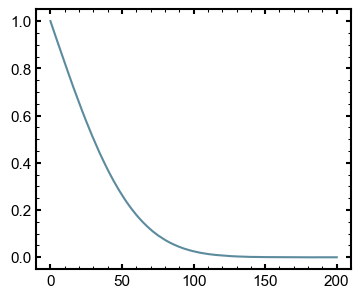

In [26]:
plt.plot(x_data, y_data_noisy, c=my_color_scale[4])

In [27]:
y_data = y_data_eval2
x_data = x_data_eval2

In [28]:
y_data = y_data - y_data.iloc[-1]

Fitted parameters: D0 = 50.08468410464415, alpha = 0.4773830829906881


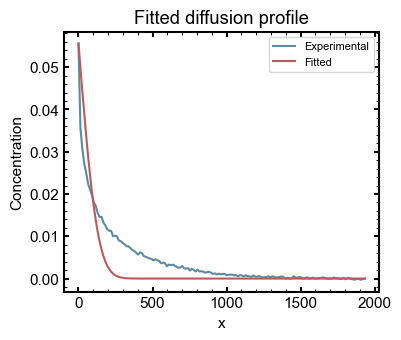

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import solve_ivp

# Diskretisierungsparameter
L = x_data.iloc[-1] # 200  # length of the considered range
Nx = len(x_data) # 200  # number of spatial grid points
dx = L / Nx  # spatial distance between the grid points
x = np.linspace(0, L, Nx)  # array of the spatial grid points

# Zeitparameter
T = 100 # Gesamte Simulationszeit
Nt = 1000  # number of time steps
dt = T / Nt  # time distance between the time steps
time_steps = np.linspace(0, T, Nt)  # array of the points in time

c0 = Step_Function_Initial_Condition(x, y_data)  # start profile of the concentration at every x = 0

# set the boundary conditions
c0[0] = y_data.iloc[0] # 1  # concentration at the left boundary
c0[-1] = 0  # concentration at the right boundary

# Experimental data (here for the demonstration the initial data with noise)
#C_exp = c0 + np.random.normal(0, 0.01, size=c0.shape)  # artificial "experimental" data
C_exp = y_data

# Initial guess for the parameters
initial_guess = [1.0, 0.1]  # Start values for the optimisation

# Optimisation of the parameters
result_diffusion_model = minimize(Objective_Diffusion_Fit, initial_guess, args=(y_data, T, c0, dx))  # Minimisation of the objective function
D0_fit, alpha_fit = result_diffusion_model.x  # fitted parameters

print(f"Fitted parameters: D0 = {D0_fit}, alpha = {alpha_fit}")

# Plot the results
C_sim = Solve_Diffusion(D0_fit, alpha_fit, T, c0, dx)  # Simulated concentration with the fitted parameters
plt.plot(x, C_exp, '-', c=my_color_scale[4], label='Experimental')  # Experimental data
plt.plot(x, C_sim, '-', c=my_color_scale[0], label='Fitted')  # Simulated data
plt.legend()
plt.xlabel('x')
plt.ylabel('Concentration')
plt.title('Fitted diffusion profile')
plt.show()

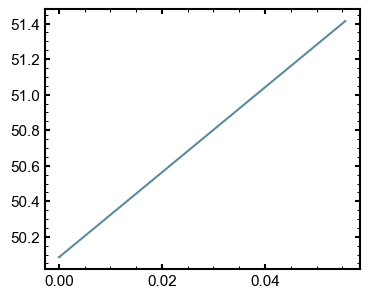

In [30]:
plt.plot(C_sim, D0_fit*(1+alpha_fit*C_sim))

In [31]:




report_fit(result)

[[Fit Statistics]]
    # fitting method   = basinhopping
    # function evals   = 1778
    # data points      = 150
    # variables        = 1
    chi-square         = 0.01847337
    reduced chi-square = 1.2398e-04
    Akaike info crit   = -1348.30906
    Bayesian info crit = -1345.29843
##  Warning: uncertainties could not be estimated:
[[Variables]]
    D:  117.721103 (init = 0.25)
    A:  0.0135 (fixed)
    t:  604800 (fixed)
